<!-- d2l:prose id=training-recipes-md-1 fw=all -->

# Modern Training Recipes for Convnets

Throughout this chapter we have worked hard to hold the training procedure
constant within each section so that accuracy differences could be attributed
to architecture. Even under those controlled conditions, simply changing the
peak learning rate shifted VGG's accuracy by 1.5 percentage points
(that section). Published benchmarks are often far less controlled: a
newly proposed network is trained with the latest optimization and
regularization tricks, then compared against a classic baseline whose accuracy
is copied from a paper written years earlier. How much of a reported
breakthrough actually comes from the *training recipe* (the optimizer,
learning-rate schedule, data augmentation, regularization, and training
duration) rather than from the architecture itself?

ResNet-50, the deeper sibling of the ResNet-18 we built in
that section, supplies a striking answer. Without altering a single
layer of the 2015 architecture, @wightman2021resnet retrained
ResNet-50 using early-2020s training practices and lifted its ImageNet top-1
accuracy from 76.1% to 80.4%—a 4.3-point jump driven purely by the training
recipe. That gain rivals or exceeds the improvements claimed by many novel
architectures published over the intervening years. Consequently, whenever a
paper claims a two-point win over a baseline trained with an outdated recipe,
we cannot tell whether the architecture or the recipe deserves the credit.

In this section, we examine what changed between 2015 and 2022, implement
each core ingredient in a few lines of code, and train an identical ResNet-18
under both a classic and a modern recipe to observe the difference directly.
None of these techniques is tied to convolutions: the exact same toolkit powers
modern Transformer training, making this a general foundation for modern deep
learning practice.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import random

<!-- d2l:prose id=training-recipes-md-2 fw=all -->

## Training Recipes from 2015 to 2022

The original 2015 ResNet recipe was already thoughtfully tuned: SGD with
momentum (that section), weight decay, step-wise learning-rate
decay (dividing by 10 twice), and random cropping with horizontal flips
[@He.Zhang.Ren.ea.2016]. Over the next several years, researchers
revisited every single piece of that pipeline—first individually and then in
large-scale systematic combinations
[@He.Zhang.Zhang.ea.2019; @wightman2021resnet].
the table contrasts the 2015 baseline with a
representative early-2020s recipe; we unpack and implement each new component
immediately below.

:A 2015 ImageNet recipe and a representative high-accuracy recipe from the
early 2020s. The later column is not a universal standard; strong recipes still
vary by model and compute budget.

| Ingredient | 2015 recipe | 2022 recipe |
|:--|:--|:--|
| Optimizer | SGD with momentum | AdamW or LAMB; tuned SGD remains competitive |
| Schedule | step decay (divide by 10 twice) | cosine decay with linear warmup |
| Augmentation | random crops, horizontal flips | RandAugment, Mixup, CutMix, random erasing |
| Regularization | weight decay | + label smoothing, stochastic depth |
| Duration | 90 epochs | 300 to 600 epochs |
| Evaluated weights | final weights | exponential moving average of the weights |

Two observations are essential when reading the table.
First, its rows interact tightly rather than acting in isolation. Stronger
data augmentation and regularization make the training objective harder to
fit, which in turn demands far more training epochs—explaining why training
schedules grew from 90 epochs to 300--600. Regularization strength and
training duration must scale together: piling heavy augmentation onto a short
run frequently *hurts* accuracy compared with a lighter recipe.

Second, the optimizer row reflects an expanded set of options rather than a
one-size-fits-all mandate. Adaptive optimizers such as Adam (covered in full
in that section) normalize each parameter's gradient by a
running estimate of its magnitude so every coordinate updates at roughly the
learning rate's scale. Classic implementations folded weight decay into the
gradient before this rescaling, inadvertently distorting the penalty. *AdamW*
[@Loshchilov.Hutter.2019] decouples weight decay from the adaptive
gradient step, shrinking every weight directly by a fraction equal to
learning rate times decay—a clean fix that made adaptive optimizers
competitive with well-tuned SGD across vision benchmarks. (LAMB is a
large-batch cousin of AdamW. The 80.4% ResNet-50 above was trained with it,
for 600 epochs, with a binary cross-entropy loss and without weight
averaging. We will not need it here.)

## Implementing the Ingredients

Each modern ingredient takes only a few lines of code. Below we implement
label smoothing, cosine warmup schedules, Mixup, stochastic depth, and
exponential weight averaging. (We omit RandAugment [@cubuk2020randaugment],
which applies random sequences of standard image transforms at a tuned
intensity, since in practice it is invoked as a preprocessing library call
whose value lies in tuning rather than implementation.)

### Label Smoothing

Under standard cross-entropy with one-hot targets, the loss on a correctly
classified example keeps falling without bound as the true class's logit
grows toward $+\infty$. Because no finite logits minimize the objective, the
network is continually pushed toward extreme, poorly calibrated confidence.
*Label smoothing* [@Szegedy.Vanhoucke.Ioffe.ea.2016] curbs this by
replacing the hard one-hot target with a softened distribution that places
weight $1-\epsilon$ on the true class $y$ and spreads $\epsilon$ uniformly
across all $K$ classes. Writing $p_k$ for the predicted softmax probabilities,
the per-example loss becomes

$$
l_\epsilon = -(1-\epsilon) \log p_y - \frac{\epsilon}{K} \sum_{k=1}^K \log p_k.
$$

The first term is ordinary cross-entropy scaled by $1-\epsilon$, while the
second penalizes pushing any class probability toward zero. The loss achieves
its minimum at $p_y = 1-\epsilon+\epsilon/K$ and $p_k = \epsilon/K$ for
$k \neq y$, which corresponds to a clean, finite margin between logits. Look
at what happens to an already confident, correct prediction under unsmoothed
versus smoothed cross-entropy:

In [3]:
logits, y = d2l.tensor([[10.0, 0.0, 0.0]]), d2l.tensor([0])
for epsilon in (0.0, 0.1):
    loss = F.cross_entropy(logits, y, label_smoothing=epsilon)
    print(f'epsilon={epsilon}: loss={float(loss):.4f}')

epsilon=0.0: loss=0.0001
epsilon=0.1: loss=0.6668


<!-- d2l:prose id=training-recipes-md-3 fw=all -->

With $\epsilon = 0.1$, the loss jumps from 0.0001 to 0.67. For three classes,
the minimum possible smoothed loss is roughly 0.29, attained when the winning
logit leads the others by about 3.3. A margin of 10 is therefore penalized as
overconfident, reversing the gradient so it pulls extreme logits back toward
a moderate gap rather than pushing them further apart.

### Cosine Schedules with Warmup

Traditional step schedules hold the learning rate constant for dozens of
epochs and then drop it abruptly by a factor of 10—introducing the drop epochs
as extra hyperparameters to tune. The modern default
[@Loshchilov.Hutter.2016] is already familiar from AlexNet onward
(that section): a linear *warmup* from 0 to the peak rate $\eta_0$
over $t_\textrm{w}$ steps, followed by a smooth half-cosine *decay*
down to 0 at step $T$. Beyond preventing early
divergence, warmup gives running batch-normalization statistics and adaptive
optimizer moments time to settle before full-size steps begin, while cosine
decay removes abrupt drop thresholds altogether. Below we plot `step_decay`
(30 epochs, with a two-epoch warmup) alongside `d2l.cosine_warmup` (45 epochs,
three-epoch warmup) at 79 minibatches per epoch, matching the exact horizons used in
our experiment later in this section.

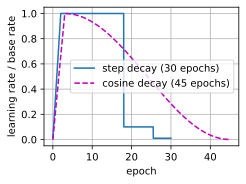

In [4]:
def step_decay(t, num_steps, warmup_steps):
    """Recipe A: linear warmup, then divide by 10 at 60% and 85% of steps."""
    warmup = min((t + 1) / warmup_steps, 1)
    return warmup * 0.1 ** sum(t >= int(f * num_steps) for f in (0.6, 0.85))

steps_per_epoch = 79
steps_a = list(range(30 * steps_per_epoch))  # Recipe A: 30 epochs
steps_b = list(range(45 * steps_per_epoch))  # Recipe B: 45 epochs
d2l.plot([[t / steps_per_epoch for t in steps_a],
          [t / steps_per_epoch for t in steps_b]],
         [[step_decay(t, len(steps_a), 2 * steps_per_epoch) for t in steps_a],
          [float(d2l.cosine_warmup(t, len(steps_b), 3 * steps_per_epoch))
           for t in steps_b]],
         xlabel='epoch', ylabel='learning rate / base rate',
         legend=['step decay (30 epochs)', 'cosine decay (45 epochs)'])

<!-- d2l:prose id=training-recipes-md-4 fw=all -->

### Mixup

*Mixup* [@zhang2018mixup] regularizes a classifier by training on convex
combinations of pairs of training examples. For each minibatch, it samples a
mixing coefficient $\lambda \sim \mathrm{Beta}(\alpha, \alpha)$ and pairs
each example $i$ with a randomly shuffled partner $j$, constructing

$$
\begin{aligned}
\tilde{\mathbf{x}} &= \lambda \mathbf{x}_i + (1-\lambda) \mathbf{x}_j, \\
\tilde{\mathbf{y}} &= \lambda \mathbf{y}_i + (1-\lambda) \mathbf{y}_j,
\end{aligned}
$$

where $\mathbf{y}_i$ and $\mathbf{y}_j$ are one-hot class vectors so
$\tilde{\mathbf{y}}$ is a soft target distribution. Because cross-entropy is
linear in its target distribution, the loss on $\tilde{\mathbf{y}}$ equals
the $\lambda$-weighted sum of the cross-entropies against $y_i$ and $y_j$,
which is simpler and faster to compute. Encouraging predictions to interpolate
linearly between training pairs discourages sharp memorization around
individual points. With typical small values ($\alpha \in [0.1, 0.2]$), the
Beta distribution concentrates near 0 and 1, leaving most minibatches lightly
perturbed while strongly blending a few. Below we implement `mixup` using one
shared $\lambda$ per minibatch and save it to `d2l` for reuse in
that section.

In [5]:
def mixup(X, y, alpha):
    """Mix a minibatch with a shuffled copy; return both label sets."""
    lam = random.betavariate(alpha, alpha)
    perm = torch.randperm(X.shape[0], device=X.device)
    return lam * X + (1 - lam) * X[perm], y, y[perm], lam

<!-- d2l:prose id=training-recipes-md-5 fw=all -->

To visualize the effect clearly, we mix a minibatch of Fashion-MNIST garments
with $\alpha = 2$, which concentrates $\lambda$ near 0.5 (training uses a much
smaller $\alpha$). The top row shows the original images and the bottom row
shows their superposed mixtures.

lambda = 0.81


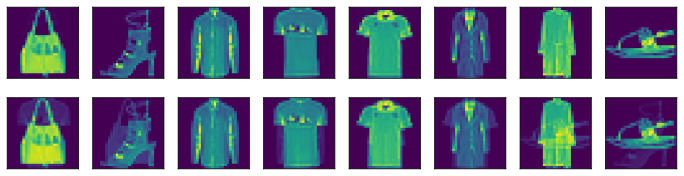

In [6]:
data = d2l.FashionMNIST(batch_size=8)
X, y = next(iter(data.train_dataloader()))
X_mix, y_a, y_b, lam = mixup(X, y, alpha=2.0)
d2l.show_images(torch.cat([X, X_mix]).squeeze(1), 2, 8)
print(f'lambda = {lam:.2f}')

<!-- d2l:prose id=training-recipes-md-6 fw=all -->

Because Mixup creates ghostly double exposures that never occur in real
photographs, *CutMix* [@yun2019cutmix] blends spatially instead: it cuts
a rectangular patch from one image, pastes it onto another, and mixes the
labels in proportion to the patch's area, keeping every pixel locally
realistic. Many modern vision recipes randomly alternate between Mixup and
CutMix from minibatch to minibatch (see the exercises below).

### Stochastic Depth

While dropout (that section) randomly zeroes out individual
activations during training, *stochastic depth*
[@huang2016stochasticdepth] drops entire residual branches at random:
with probability $p$, a block's residual branch is bypassed so the block
passes its input straight through, effectively training an ensemble of
shallower subnetworks. Residual connections make this safe because the
identity shortcut always keeps the signal flowing. For a block computing
$\mathbf{x} + f(\mathbf{x})$, stochastic depth replaces the branch with

$$
\mathbf{x} + \frac{b}{1 - p} f(\mathbf{x}), \qquad b \sim \mathrm{Bernoulli}(1-p).
$$

Just as in inverted dropout, scaling by $1/(1-p)$ keeps the expected branch
output unchanged during training so no rescaling is needed at evaluation time.
Modern implementations sample $b$ independently for every example in the
minibatch (`drop_path` below, saved to `d2l` for ConvNeXt). Subclassing
`d2l.Residual` (that section), we drop the residual branch right
before adding the shortcut; passing 1,000 random inputs through the block in
training mode with $p = 0.5$, roughly half of all outputs should match
$\mathrm{ReLU}(\mathbf{x})$ identically.

In [7]:
def drop_path(Y, p, training):
    """Zero each example of Y with probability p, rescale the rest."""
    if not training or p == 0:
        return Y
    shape = (Y.shape[0],) + (1,) * (Y.ndim - 1)  # One draw per example
    keep = torch.rand(shape, device=Y.device) > p
    return Y * keep / (1 - p)

class StochasticResidual(d2l.Residual):
    """A residual block whose branch is dropped with probability p."""
    def __init__(self, num_channels, p):
        super().__init__(num_channels)
        self.p = p

    def forward(self, X):
        Y = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(X)))))
        return F.relu(X + drop_path(Y, self.p, self.training))

blk, X = StochasticResidual(3, p=0.5), torch.randn(1000, 3, 8, 8)
Y = blk(X)  # A module is in training mode until .eval() is called
dropped = (Y == F.relu(X)).flatten(1).all(1).float().mean()
print(f'fraction of examples with a dropped branch: {float(dropped):.3f}')

fraction of examples with a dropped branch: 0.473


<!-- d2l:prose id=training-recipes-md-7 fw=all -->

In deep architectures, the drop probability $p$ typically ramps linearly from
0 in the earliest block to a peak of 0.1--0.5 in the deepest block. Notice
that per-example masking still evaluates every branch before zeroing out
dropped examples, so it regularizes without speeding up training; the original
per-minibatch formulation draws a single $b$ per block and can skip dropped
branches completely to save compute.

### Averaging Weights

The final row of the table delivers cleaner generalization
at virtually zero extra cost. Near the end of training, minibatch noise causes
parameters to bounce around the floor of a low-loss basin, so averaging recent
iterates lands closer to the basin's center than any single checkpoint.
Whereas *stochastic weight averaging* (SWA)
[@Izmailov.Podoprikhin.Garipov.ea.2018] averages snapshots uniformly late
in training, modern vision recipes commonly maintain an *exponential moving
average* (EMA), the exact same recursion batch normalization uses for its
running statistics (that section). After every optimizer step, a
*shadow copy* $\bar{\theta}$ of the trainable parameters blends in the latest
weights $\theta$ with decay $\rho$:

$$
\bar{\theta} \leftarrow \rho \bar{\theta} + (1-\rho) \theta.
$$

Parameters from $k$ steps ago carry weight $(1-\rho)\rho^k$, giving an
effective averaging horizon of roughly $1/(1-\rho)$ steps (100 steps for
$\rho = 0.99$). Optimization continues updating $\theta$ as usual, while
evaluation swaps in $\bar{\theta}$. (Because batch-normalization running
statistics are buffers rather than trainable weights, an exercise below
examines how best to pair them with EMA weights.) To see the tradeoff in
$\rho$, let us track a single synthetic weight that climbs from 0 to 1 over
50 steps and then oscillates noisily around 1.

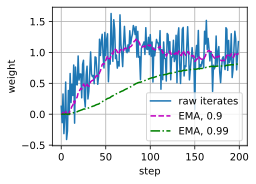

In [8]:
class EMA:
    """A shadow copy of a model's parameters, updated after each step."""
    def __init__(self, model, decay=0.99):
        self.decay = decay
        self.shadow = {k: p.detach().clone()
                       for k, p in model.named_parameters()}

    @torch.no_grad()
    def update(self, model):
        for k, p in model.named_parameters():
            self.shadow[k].lerp_(p, 1 - self.decay)  # beta*avg + (1-beta)*p

net = nn.Linear(1, 1, bias=False)
nn.init.zeros_(net.weight)  # Training starts at 0
emas = {decay: EMA(net, decay) for decay in (0.9, 0.99)}
raw, avg = [], {decay: [] for decay in emas}
for t in range(200):  # Iterates rise to 1 over 50 steps, then stay noisy
    with torch.no_grad():
        net.weight.copy_(min(t / 50, 1) + 0.3 * torch.randn(1, 1))
    raw.append(float(net.weight.detach()))
    for decay, ema in emas.items():
        ema.update(net)
        avg[decay].append(float(ema.shadow['weight']))
d2l.plot(list(range(200)), [raw, *avg.values()], xlabel='step',
         ylabel='weight', legend=['raw iterates', 'EMA, 0.9', 'EMA, 0.99'])

<!-- d2l:prose id=training-recipes-md-8 fw=all -->

At $\rho = 0.9$ (horizon ~10 steps), the shadow weight trails the ramp by
about 10 steps and then dramatically damps out the noise. At $\rho = 0.99$
(horizon ~100 steps), it is smoother still, yet lags so far behind that it
still sits roughly 20% below 1 after 200 steps. That illustrates the main
pitfall of EMA: whenever $1/(1-\rho)$ is large compared with the run length,
the shadow copy lags behind improving weights and underperforms the final
checkpoint. Very large decays like 0.999 or 0.9999 therefore belong only in
long training runs.

## Two Recipes on One Network

Now let us assemble these pieces and run a head-to-head test on a single
fixed architecture: the ResNet-18 of that section, rebuilt from
`d2l.Residual` with He initialization (that section). We
train on a random subset of 10,000 Fashion-MNIST images resized to
$96 \times 96$ (shared by both recipes within each run): using fewer training
examples amplifies the role of regularization while keeping repeated
experiments fast. Both recipes compute their step schedules directly from
`lr` and `num_steps`.

In [9]:
class FashionMNIST10k(d2l.FashionMNIST):
    """Fashion-MNIST with a random subset of num_train training images."""
    def __init__(self, batch_size=128, resize=(96, 96), num_train=10000):
        super().__init__(batch_size, resize)
        idx = torch.randperm(len(self.train))[:num_train]
        self.train.data = self.train.data[idx]  # get_dataloader reads these
        self.train.targets = self.train.targets[idx]

class ResNet18(d2l.Classifier):
    """The ResNet-18 of the residual-networks section, from d2l.Residual."""
    def __init__(self, lr, num_steps, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        layers = [nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3,
                                bias=False),
                  nn.LazyBatchNorm2d(), nn.ReLU(),
                  nn.MaxPool2d(kernel_size=3, stride=2, padding=1)]
        for i, c in enumerate((64, 128, 256, 512)):
            for j in range(2):
                down = i > 0 and j == 0
                layers.append(d2l.Residual(c, use_1x1conv=down,
                                           strides=2 if down else 1))
        layers += [nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
                   nn.LazyLinear(num_classes)]
        self.net = nn.Sequential(*layers)

    def weight_init(self, module):  # The Trainer applies it after a dry run
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)  # Variance 2/n_in
            if module.bias is not None:
                nn.init.zeros_(module.bias)

<!-- d2l:prose id=training-recipes-md-9 fw=all -->

Both models share the exact same architecture and training split while
changing the optimization and regularization recipe completely. *Recipe A*
mirrors 2015 practice: SGD with momentum 0.9, coupled weight decay
$5 \times 10^{-4}$, a peak learning rate of 0.05 with two epochs of linear
warmup followed by 10-fold drops at 60% and 85% of training, plain
cross-entropy loss, and 30 epochs. (The short two-epoch warmup is a minor
modern stabilization, introduced for large-minibatch SGD by
@Goyal.Dollar.Girshick.ea.2017: without it, batch-normalized SGD at
0.05 diverged in epoch 1 in roughly a third of our runs.)
Our *compact modern recipe* uses AdamW with weight decay 0.05, peak learning
rate 0.002 with three epochs of warmup and cosine decay, label smoothing
($\epsilon = 0.1$), Mixup ($\alpha = 0.2$), and 45 epochs (reflecting the
longer horizon modern regularization requires). To keep runtime manageable, it
omits RandAugment, CutMix, stochastic depth, and EMA, testing a lean subset of
the full menu.

Do not be misled by the 100-fold gap between the two weight-decay numbers
(0.05 vs. $5 \times 10^{-4}$). The actual fractional shrinkage per step is
learning rate times weight decay: at peak rate, that equals
$0.002 \times 0.05 = 10^{-4}$ for AdamW versus
$0.05 \times 5 \times 10^{-4} = 2.5 \times 10^{-5}$ for SGD—which momentum
amplifies up to tenfold, making SGD's effective decay actually stronger.
Finally, both recipes evaluate validation loss using plain cross-entropy on
unmixed validation images; label smoothing and Mixup modify only the training
objective.

In [10]:
class ClassicRecipe(ResNet18):
    """Recipe A: SGD with momentum, weight decay, warmup, step decay."""
    def configure_optimizers(self):
        optim = torch.optim.SGD(self.parameters(), lr=self.lr, momentum=0.9,
                                weight_decay=5e-4)
        warmup = 2 * self.num_steps // 30  # Two of the 30 epochs
        return optim, torch.optim.lr_scheduler.LambdaLR(
            optim, lambda t: step_decay(t, self.num_steps, warmup))

class ModernRecipe(ResNet18):
    """Compact modern recipe: AdamW, warmup and cosine, smoothing, Mixup."""
    def configure_optimizers(self):
        warmup = 3 * self.num_steps // 45  # Three of the 45 epochs
        optim = torch.optim.AdamW(self.parameters(), lr=self.lr,
                                  weight_decay=0.05)
        return optim, torch.optim.lr_scheduler.LambdaLR(
            optim, lambda t: d2l.cosine_warmup(t, self.num_steps, warmup))

    def training_step(self, batch):
        X, y_a, y_b, lam = mixup(*batch, alpha=0.2)
        Y_hat = self(X)
        smooth = lambda y: F.cross_entropy(Y_hat, y, label_smoothing=0.1)
        return lam * smooth(y_a) + (1 - lam) * smooth(y_b)

<!-- d2l:prose id=training-recipes-md-10 fw=all -->

First we train Recipe A for 30 epochs and evaluate on the full 10,000-image
validation split.

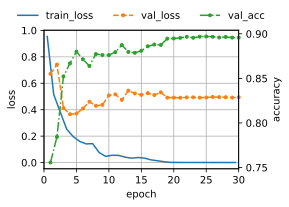

0.8958

In [11]:
data = FashionMNIST10k()
steps_per_epoch = len(data.train_dataloader())  # 79 minibatches of <= 128
model = ClassicRecipe(lr=0.05, num_steps=30 * steps_per_epoch)
trainer = d2l.Trainer(max_epochs=30, num_gpus=1)
trainer.fit(model, data)
trainer.history['val_acc'][-1]

<!-- d2l:prose id=training-recipes-md-11 fw=all -->

Next we train the exact same architecture on the exact same training subset
for 45 epochs using the compact modern recipe.

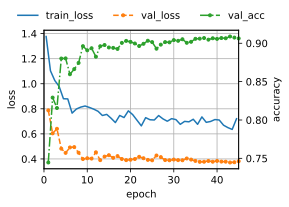

0.9063

In [12]:
model = ModernRecipe(lr=2e-3, num_steps=45 * steps_per_epoch)
trainer = d2l.Trainer(max_epochs=45, num_gpus=1)
trainer.fit(model, data)
trainer.history['val_acc'][-1]

<!-- d2l:prose id=training-recipes-md-12 fw=all -->

the table reports the validation accuracy range across
repeated runs (each drawing a fresh 10,000-image subset, initialization, and
minibatch order).

:The same ResNet-18 under both recipes (10,000 Fashion-MNIST training images at
$96 \times 96$; validation accuracy, range over repeated runs).

| Recipe | Epochs | Validation accuracy |
|:--|--:|--:|
| A (2015): SGD, warmup, step decay | 30 | 89–90.5% |
| Compact modern: AdamW, cosine, smoothing, Mixup | 45 | 90.5–91% |

In every paired run on the same 10,000-image subset, `ModernRecipe` beats `ClassicRecipe` by 0.5--1.5 percentage points (even while omitting RandAugment, CutMix, stochastic depth, and EMA). Three practical lessons accompany this comparison:

1. **Bundled comparisons vs. ablations:** Because optimizer, schedule, loss, augmentation, and epoch budget changed together, only a one-at-a-time ablation (Exercise 4) can isolate which ingredient contributed most—and because optimal learning rates differ $25\times$ between AdamW ($0.002$) and SGD ($0.05$), any optimizer swap must retune the learning rate.
2. **Never compare raw training losses across recipes:** Under `ClassicRecipe`, training loss plunges toward zero while validation loss rebounds to 0.4--0.5 as logits grow overconfident; under `ModernRecipe`, validation loss drops below 0.4 while training loss stays *higher* than validation loss because Mixup and label smoothing evaluate a soft, blended training objective.
3. **Reading published leaderboards:** Because training recipes alone move a fixed ResNet-50 by $>4$ ImageNet points [@wightman2021resnet], a 1-point claim over a baseline copied from an older paper confounds recipe with architecture. Even under matched recipes, test-set noise and multi-object ambiguity on ImageNet [@Recht.Roelofs.Schmidt.ea.2019; @beyer2020imagenetreal] mean that transfer to detection or segmentation is often a sharper test of backbone quality than sub-point ImageNet top-1 deltas.

## Summary

Between 2015 and the early 2020s, convnet training recipes evolved across every axis: adaptive optimizers with decoupled weight decay (AdamW, LAMB), cosine warmup schedules, RandAugment/Mixup/CutMix, label smoothing, stochastic depth, longer training horizons, and EMA weight averaging. One such recipe (LAMB, a cosine schedule, RandAugment with Mixup and CutMix, stochastic depth, 600 epochs, and no weight averaging) lifted an unchanged ResNet-50 from 76.1% to 80.4% on ImageNet. Each ingredient takes only a few lines of code, and a compact subset reliably improves ResNet-18 on `FashionMNIST10k`. Next, that section holds the modern recipe fixed and modernizes the ResNet architecture itself one step at a time.

## Exercises

1. **Binary cross-entropy and Mixup.** @wightman2021resnet train ImageNet classifiers with binary cross-entropy (treating each of the $K$ classes as an independent sigmoid binary classification task) rather than $K$-way softmax cross-entropy. Explain why independent sigmoid outputs pair naturally with Mixup and CutMix when a blended image contains objects from two distinct classes at once.

1. [code] **CutMix.** CutMix [@yun2019cutmix] samples $\lambda \sim \mathrm{Beta}(1, 1) = \mathrm{Uniform}(0, 1)$ and pastes a random rectangular patch from a shuffled partner image covering a target area fraction $1 - \lambda$. Implement `cutmix` as a drop-in variant of `mixup`, mixing the one-hot labels using the *exact* fraction of pixels kept after clipping the rectangle to the image borders. Train `ModernRecipe` on `FashionMNIST10k` once with CutMix in place of Mixup and once alternating randomly between Mixup and CutMix each minibatch, and compare validation accuracy against the table.

1. [code] **Weight averaging horizon (EMA).** Integrate the `EMA` class into `ModernRecipe` by updating the shadow weights after every optimizer step and evaluating validation accuracy with the shadow parameters. Sweep the decay $\rho \in \{0.9, 0.99, 0.999\}$ in the equation. Relate the best-performing $\rho$ to the effective horizon $1/(1-\rho)$ and the total number of steps ($45 \times 79 = 3{,}555$), and explain how batch-normalization running statistics should be handled when evaluating EMA weights.

1. [code] **One-at-a-time recipe ablation.** ● In the table, `ModernRecipe` beats `ClassicRecipe` by 0.5--1.5 percentage points when all five ingredients change at once.
    1. Run both `ClassicRecipe` and `ModernRecipe` five times on `FashionMNIST10k` to estimate the run-to-run standard deviation of validation accuracy.
    1. Starting from `ModernRecipe`, revert one ingredient at a time to its `ClassicRecipe` counterpart: (i) remove Mixup, (ii) remove label smoothing, (iii) replace cosine warmup with `step_decay`, (iv) replace AdamW with momentum SGD (retuning the peak learning rate to $0.05$), and (v) shorten training from 45 to 30 epochs. Which individual changes exceed the run-to-run noise floor?
    1. Complete the $2 \times 2$ table of optimizer (SGD vs. AdamW) $\times$ schedule (`step_decay` vs. `cosine_warmup`) with Mixup and label smoothing enabled. Do the optimizer and schedule interact?

1. [code] **Stochastic depth in the recipe.** ● Our compact modern recipe omitted stochastic depth. Add it back to `ResNet18`:
    1. Extend `StochasticResidual` to support stride-2 downsampling blocks with $1 \times 1$ shortcuts, and build `ResNet18` with drop probabilities growing linearly from $0$ in block 1 to $p_{\max}$ in block 8. What is the expected number of active residual branches per forward pass as a function of $p_{\max}$?
    1. Sweep $p_{\max} \in \{0.1, 0.2, 0.5\}$ under `ModernRecipe` on `FashionMNIST10k` (compared against $p_{\max} = 0$). Why does a shallow 8-block network benefit less from large $p_{\max}$ than a 50- or 100-block network?
    1. Implement the per-minibatch variant of @huang2016stochasticdepth, which draws a single Bernoulli variable $b$ per block and skips evaluating the residual branch altogether when $b = 0$. At $p_{\max} = 0.5$, compare the theoretical fraction of skipped branches against the measured reduction in wall-clock training time.

[Discussions](https://d2l.discourse.group/t/36761)